# Did ground finch beak depths evolve on the Galápagos islands between 1976 and 1978?
<div>
<img src="Images/ground_finch.jpg" width='30%' title=""/>
</div>

### Imports

Run this code to import modules

In [2]:
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from statsmodels.formula.api import ols

### Load and print the data

First we read in the dataset and print it to see how it looks and what the variable names, types and values are.

In [14]:
beaks = pd.read_csv('../Datasets/finches beak depth.csv')
beaks

,year,depth
0,1976,9.4
1,1976,10.3
2,1976,11.2
3,1976,9.2
4,1976,10.2
...,...,...
130,1978,10.2
131,1978,8.9
132,1978,11.2
133,1978,10.1


Variable names are `year` and `depth`. 

- The variable `year` is categorical with two levels `1976` and `1978` representing the two years in which beak depth measurements were taken. Although year is numeric it is treated as categorical for this analysis. 
- The variable `depth` is a continuous numerical variable with units of mm.

Next we need to identify the explanatory (independent) and response (dependent) variables. In this case it is very simple. `year` is the explanatory variable and `depth` is the response variable. 

### Plot the data

Now lets plot the data in a seaborn swarm plot. A swarm plot is a good one here because it shows the distribution of the individual data points. A boxplot could also be used but it doesn't show individual data points and so is harder to interpret.

The explanatory variable goes on the horizontal *x*-axis and the response variable goes on the vertical *y*-axis.

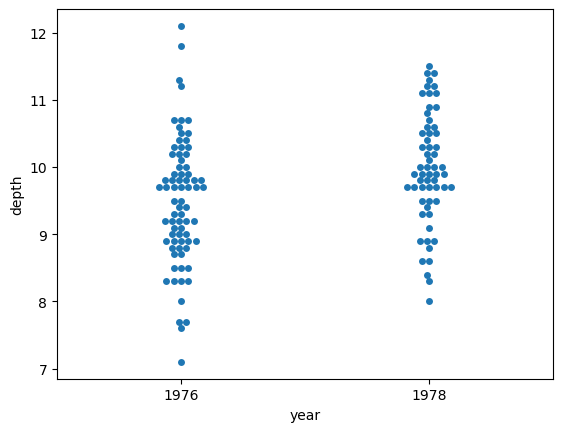

In [12]:
sns.swarmplot(data=beaks, x='year', y='depth');

### Significance testing revisited

Remember from last week that significance testing answers the question, How compatible are the data with the null hypothesis? Where the null hypothesis is a statement about no difference or no effect or no cause or no change. 

Last week you learned how to do a two-sample *t*-test using `ttest_ind()` to calculate *P*, the degree of compatibility of the data with the null hypothesis that mean beak depths do not differ between 1976 and 1978.

For reference, we'll quickly do that *t*-test again so that we can compare the results when we do a linear model.

First, we calculate the mean beak depths of the two years and their difference.

In [15]:
means = beaks.groupby('year')['depth'].mean()

print(means.round(4))
print()
print(f'difference = {means[1978]-means[1976]:.2f} mm')

year
1976    9.4880
1978    9.9817
Name: depth, dtype: float64

difference = 0.49 mm


Mean beak depths are 9.49 mm in 1976 and 9.98 mm in 1978, a difference of 0.49 mm.

Next we run the *t*-test.

In [7]:
beaks_1976 = beaks.query('year == 1976')
beaks_1978 = beaks.query('year == 1978')

test = ttest_ind(beaks_1978['depth'], beaks_1976['depth'])
print(f'degrees of freedom = {test.df:.0f}')
print(f't-statistic = {test.statistic:.2g}')
print(f'P = {test.pvalue:.2g}')

ci = test.confidence_interval()
print(f'95% CI = [{ci.low:.2g}, {ci.high:.2f}] mm')

degrees of freedom = 133
t-statistic = 3.2
P = 0.0019
95% CI = [0.19, 0.80] mm


With *P* equal to 0.002, the data are incompatible with the null hypothesis that beak depths were the same in 1976 and 1978.

Using the phrasing of classical statistics you could say that there is a statistically significant difference on 0.49 mm between 1976 and 1978 (95% CI [0.19, 0.80] mm, $t_{133}=3.2$, $p=0.002$).

### Modelling data

Linear modelling simplifies data exploration and analysis. The main advantages are:

- Unified framework: You learn one conceptual framework instead of memorising dozens of distinct, named tests (like t-tests, ANOVA, ANCOVA and χ^2^).
- Flexibility: You can mix continuous and categorical variables seamlessly in a single model.
- Handles interactions: It reveals if the effect of one variable depends on the level of another variable.
- Direct effect sizes: The method automatically provides estimates with standard errors and 95% CIs.


To make a linear model we first have to write down a model for the data. The model states how the variables we have measured could be related. In this example we have only two variables; "year" and "depth", so our model will be simple. For more complex datasets, like the project datasets you are using in this course, the models can be quite complicated. But let's start simply. 

Our simple model states that ground finch beak depth is related to the year of measurement. The model is written as a formula that the computer can understand. However, the formula is not quite like ones you've seen before such as that for a straight line $y=mx+c$. The formula for our model is written like this


    depth ~ C(year)

The squiggle `~` (also called tilde) means "is related to", so the formula reads "beak depth is related to year". In this formula the response variable "depth" appears on the left of the tilde and the explanatory variable "year" appears on the right.

The notation `C(year)` tells the computer that we are treating year as a categorical variable rather than as a numerical variable.

Of course, mean beak depth will be related to other things such as the bird's age, sex, growth rate and so on. But we haven't measured these other things so they can't appear in our model.

### Code and fit the model

Next we code the model formula, fit the model to the data and output a summary of the fit. We use a method called "ordinary least squares" (ols for short). You may have come across this at school. We are not going into the details of how ordinary least squares works. All we're interested in is its output.

In [8]:
# the model formula is coded as a string
formula = 'depth ~ C(year)'

# fit the model to the data
fit = ols(formula, beaks).fit()

# output summary table of the model fit
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,9.4880,0.104,91.554,0.000,9.283,9.693
C(year)[T.1978],0.4937,0.155,3.176,0.002,0.186,0.801


### Interpret the summary of the model fit

What does this table mean?

Let's start with the first column called "coef" (which stands for "coefficient"). This has two values, 9.4880 for the thing called `Intercept` and 0.4937 for the thing called `C(year)[T.1978]`. Compare these values to the estimated 1976 mean beak depth and the estimated difference between the 1976 and 1978 mean beak depths in this figure.

<div>
<img src="Images/beak_depths.png" width='30%'/>
</div>


They are the same. This is not a coincidence. What `ols` has done is used 1976 as a reference level, called `Intercept`, and compared it to the 1978 level called `C(year)[T.1978]`. By default `ols` choses as the reference level the level whose name comes first numerically or alphabetically. As we'll see later, we can tell `ols` which level to use as the reference level. But for now we'll just use the default behaviour of `ols`.

Each row in the above table is a *t*-test on whether the value of its "coef" is compatible with being zero, or in classical statistics terminology, whether the value of "coef" is significantly different from zero. So the first row asks "Is the 1976 mean beak depth of 9.4880 mm compatible with being zero?" and the second row asks "Is the difference of 0.4937 mm between the 1976 and 1978 means compatible with being zero?".

The `Intercept` significance test is a bit meaningless. We know that beak depths must have a size greater than zero otherwise they wouldn't exist. So we can ignore the `Intercept` test; we're not testing the null hypothesis of whether beak depths have a mean size of zero mm. (Although the `Intercept` test is meaningless in this example, it may have meaning in other cases, as we will see.)

What we are interested in though is the significance test of whether the observed difference in mean beak depths between 1978 and 1976 of 0.49 mm is compatible with being zero.

The value of *P* for that test is given in the "P>|t|" column. 

Looking at the table we see that *P* is 0.002 — exactly the same value we got when we used `ttest_ind()`. Also notice that the value of *t* is the same at 3.2. 

The last two columns of the summary table give the 95% CI of the coefficient. This is [0.19, 0.80] mm. Again, the same as we got using `ttest_ind()`.

### Report the outcome of the test

> A statistically significant increase in ground finch beak depths of 0.49 mm (95% CI [0.19, 0.80] mm) occurred between 1976 and 1978 ($t_{133}=3.2$, $p=0.002$).

Or, if you don't like classical statistics terminology, and you want to be neutral and let the reader judge the evidence for themselves, you could write, for example:

> Ground finch beak depths increased by 0.49 ± 0.16 mm (mean±SEM) between 1976 and 1978 ($t_{133}=3.2$, $p=0.002$).

How you report your results is up to you. But notice we report the estimate, the error (as SEM or 95% CI), the test-statistic (*t*), the degrees of freedom (133) and *P*. These should always be reported so that readers know how you have analysed your data.

### Changing the reference level of the Intercept

I mentioned above that we can change which level `ols` uses as the reference level for `Intercept`. By default `ols` choses the level whose name comes first numerically or alphabetically as the reference level. "1976" is the reference level because it comes before "1978" numerically. To make "1978" the reference level we have to change the model formula like so:

    depth ~ C(year, Treatment(reference=1))
    

In [9]:
formula = 'depth ~ C(year, Treatment(reference=1))'
fit = ols(formula, beaks).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,9.9817,0.116,86.149,0.000,9.752,10.211
"C(year, Treatment(reference=1))[T.1976]",-0.4937,0.155,-3.176,0.002,-0.801,-0.186


`reference=0` sets "1976" level to the reference level and `reference=1` sets "1978" level to the reference level. 

Notice when "1978" is the reference level, "coef" of `Intercept` is 9.98 mm; the estimated mean beak depth of the 1978 ground finches (see the above figure). Also the difference is now negative 0.49 mm because we are subtracting 9.98 mm from 9.49 mm, not the other way round when "1976" was the reference level.

In this case it doesn't matter which reference level is used; the outcome is still the same. However, sometimes it makes more sense to use a particular level as the reference level.